# Final Project: House Price Prediction

This project simulates an end-to-end Machine Learning workflow to predict house prices in California based on various features like location, number of rooms, and median income. It follows the 12-step real-world data science pipeline.

## Step 1: Problem Definition
- **Business Problem:** Predict house prices to help real estate agents and buyers make informed decisions.
- **Prediction:** We are predicting `MedHouseVal` (Median House Value) which is a continuous variable (Regression).
- **Benefits:** Optimizing pricing strategies, understanding feature importance (like location and income).

## Step 2: Data Collection / Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_csv('california_housing.csv')
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Step 3: Data Cleaning

In [2]:
# Check for missing values
print('Missing values:', df.isnull().sum().sum())

# Remove duplicates
df = df.drop_duplicates()

# Check data types
df.info()

Missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


## Step 4: Exploratory Data Analysis (EDA)

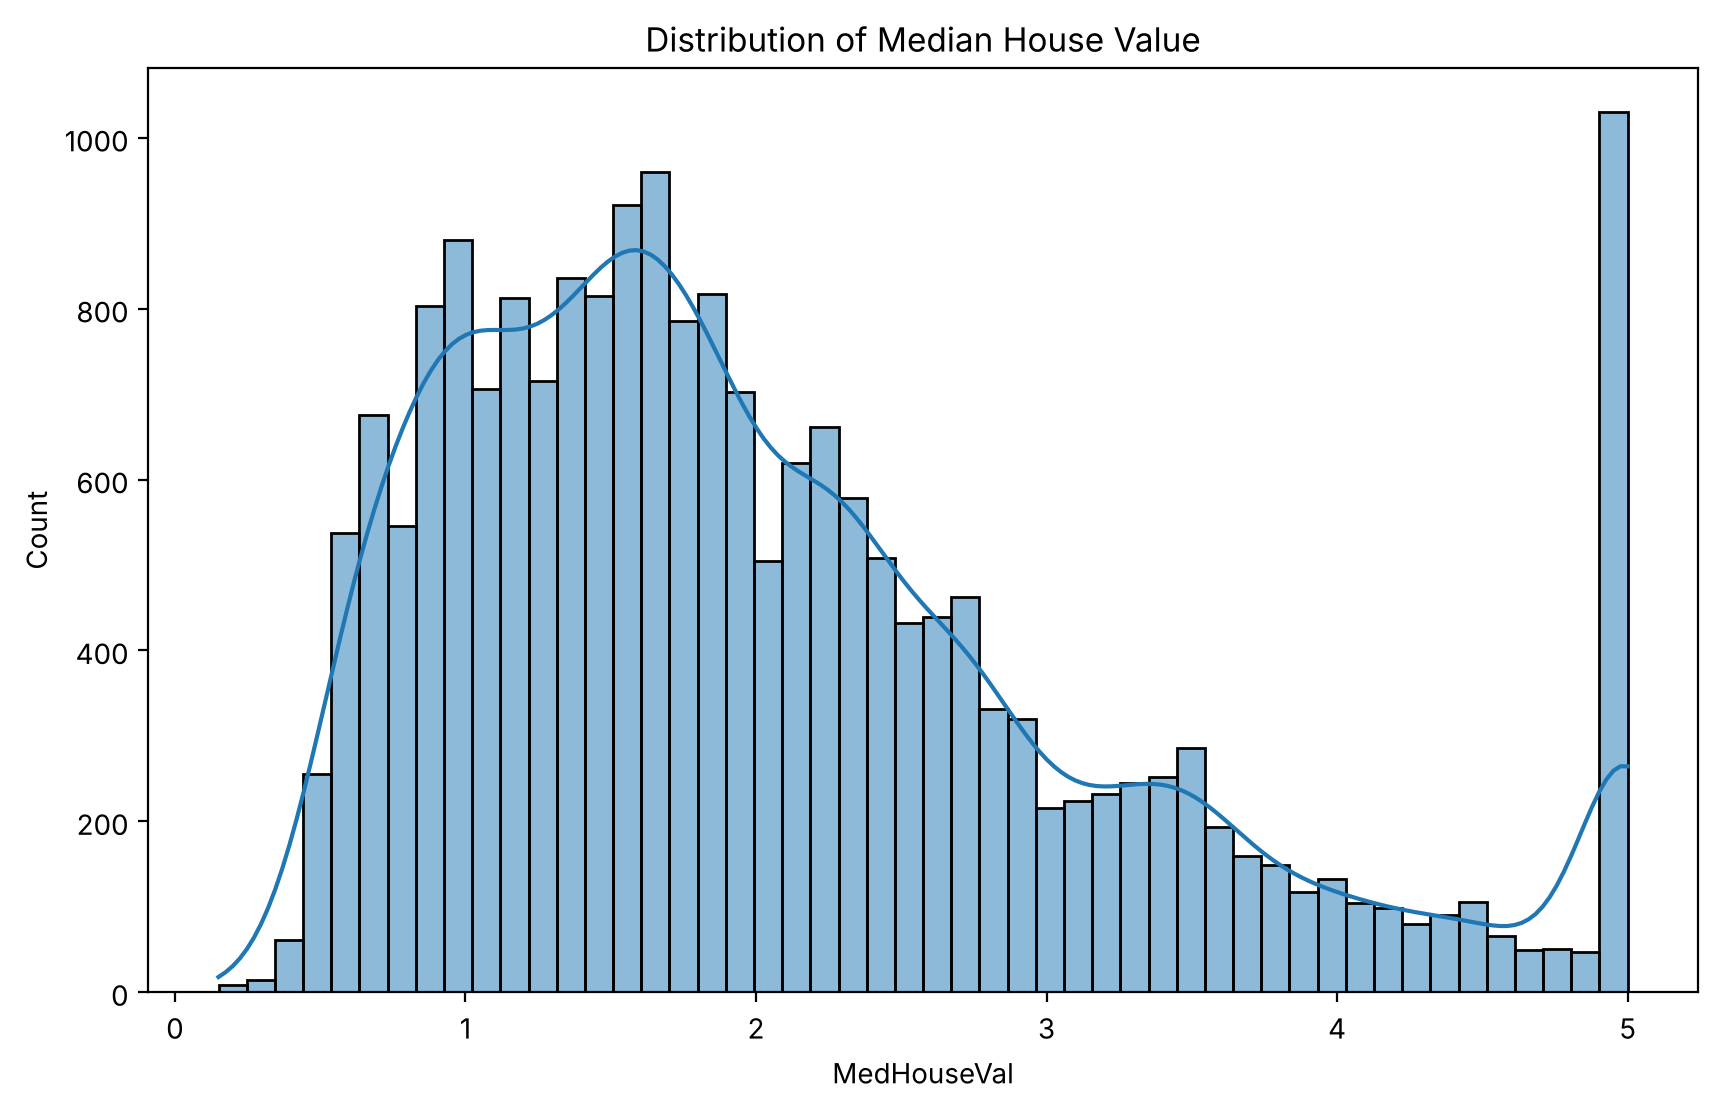

In [3]:
plt.figure(figsize=(10, 6))
sns.histplot(df['MedHouseVal'], bins=50, kde=True)
plt.title('Distribution of Median House Value')
plt.show()

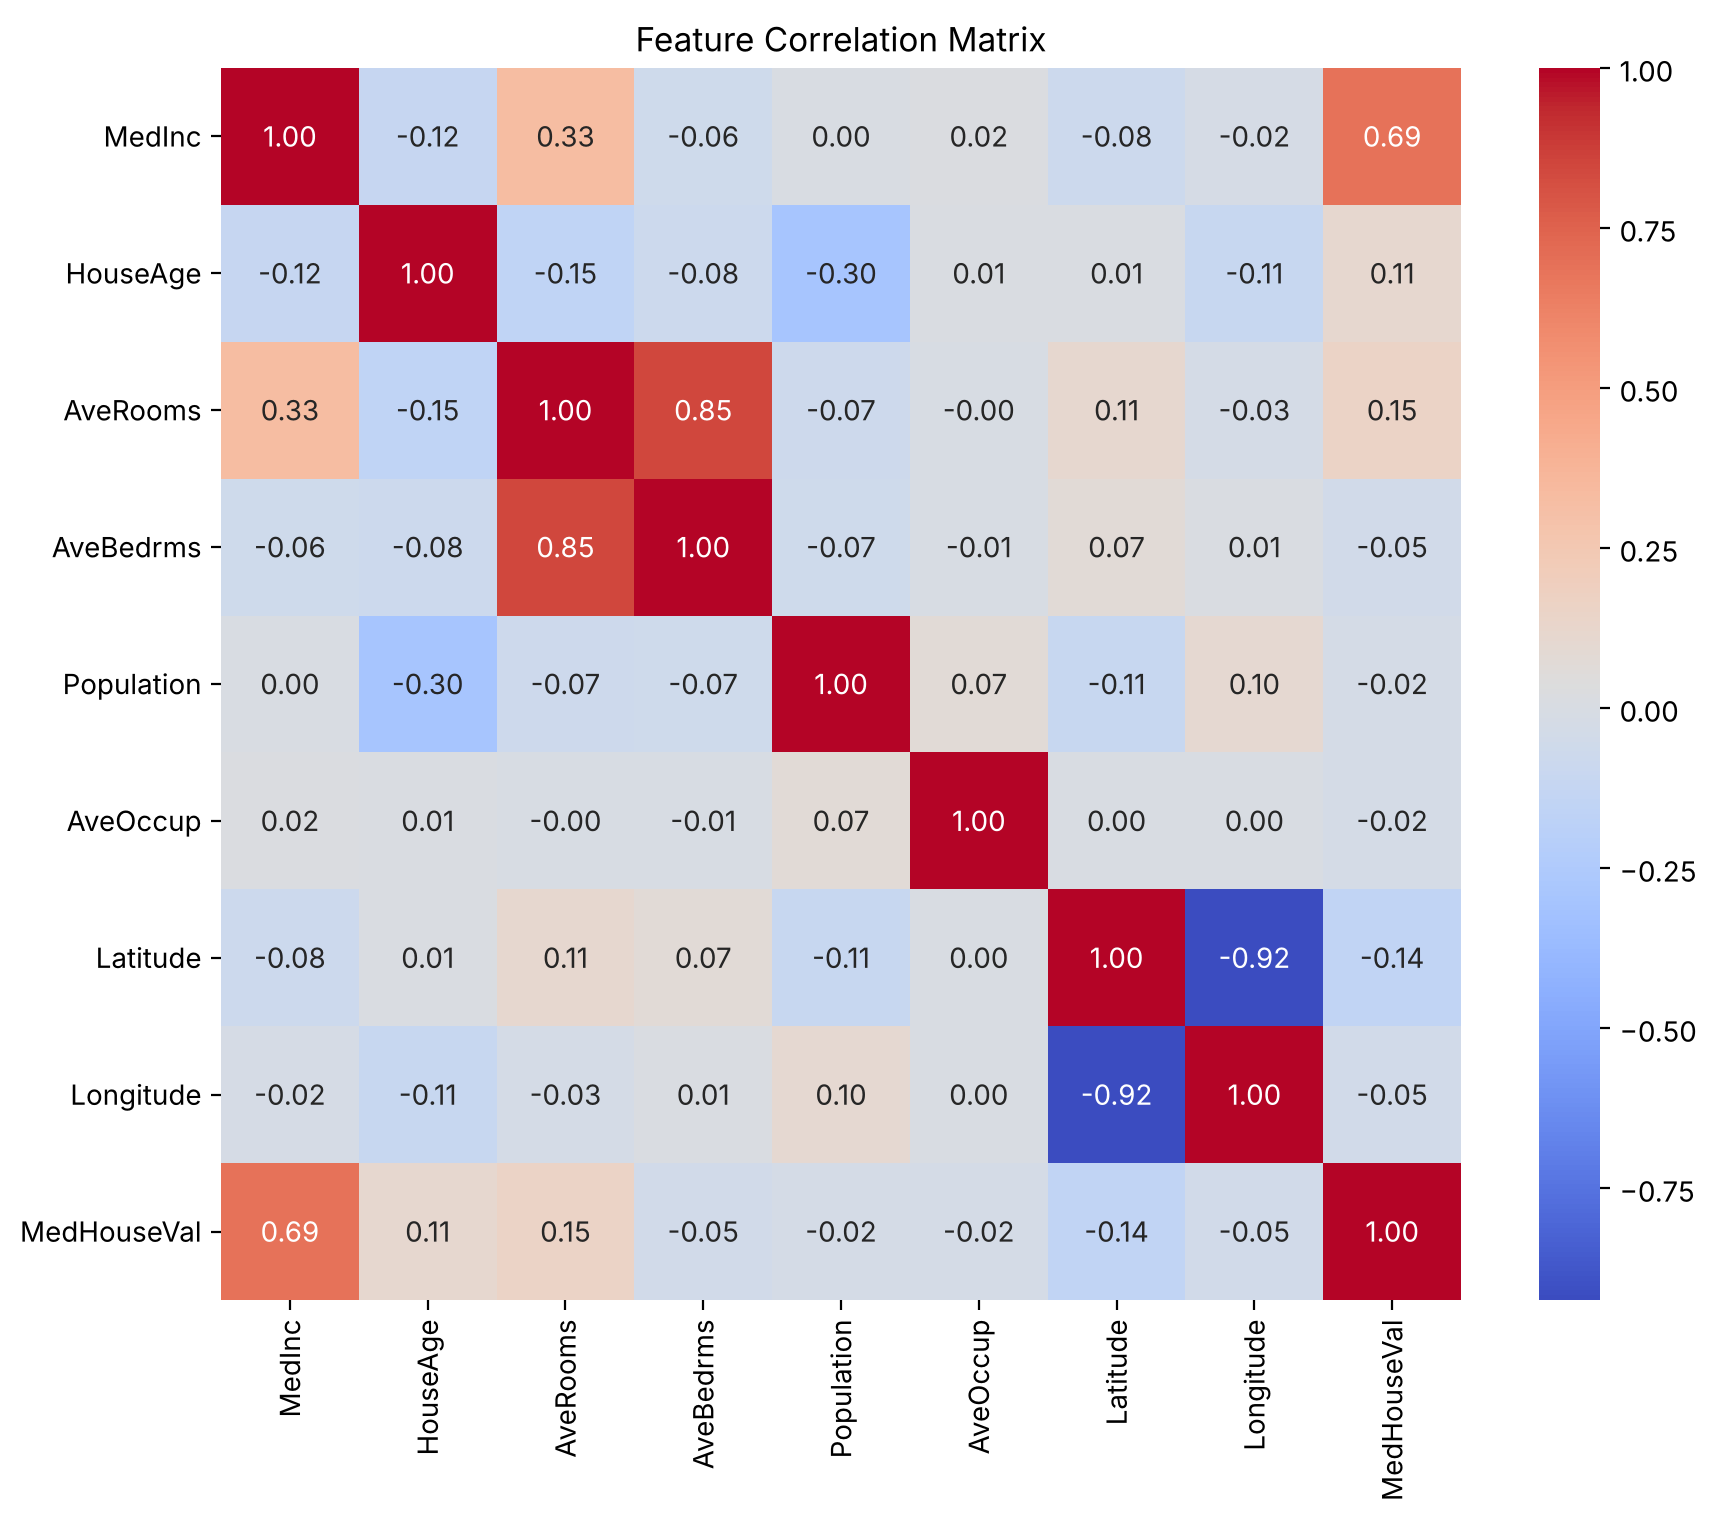

In [4]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

## Step 5: Feature Engineering

In [5]:
from sklearn.preprocessing import StandardScaler

X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,2.344766,0.982143,0.628559,-0.153758,-0.974429,-0.049597,1.052548,-1.327835
1,2.332238,-0.607019,0.327041,-0.263336,0.861439,-0.092512,1.043185,-1.322844
2,1.782699,1.856182,1.155620,-0.049016,-0.820777,-0.025843,1.038503,-1.332827
3,0.932968,1.856182,0.156966,-0.049833,-0.766028,-0.050329,1.038503,-1.337818
4,-0.012881,1.856182,0.344711,-0.032906,-0.759847,-0.085616,1.038503,-1.337818


## Step 6: Splitting the Data

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
print(f'Training shape: {X_train.shape}')
print(f'Testing shape: {X_test.shape}')

Training shape: (16512, 8)
Testing shape: (4128, 8)


## Step 7: Model Selection and Training
We'll evaluate Linear Regression and Random Forest.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_preds = lr.predict(X_test)

# Random Forest
rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

## Step 8: Model Evaluation

In [8]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'{name} - RMSE: {rmse:.4f}, R2: {r2:.4f}')

evaluate_model('Linear Regression', y_test, lr_preds)
evaluate_model('Random Forest', y_test, rf_preds)

Linear Regression - RMSE: 0.7456, R2: 0.5758
Random Forest - RMSE: 0.5070, R2: 0.8038


## Step 9: Hyperparameter Tuning
We will use GridSearchCV to tune the Random Forest model.

In [9]:
from sklearn.model_selection import GridSearchCV

# Defining a smaller grid for faster execution
params = {'n_estimators': [50, 100], 'max_depth': [10, 20, None]}
grid = GridSearchCV(RandomForestRegressor(random_state=42), params, cv=3, scoring='r2', n_jobs=-1)
grid.fit(X_train, y_train)

print('Best Parameters:', grid.best_params_)

Best Parameters: {'max_depth': None, 'n_estimators': 100}


## Step 10: Final Model Training and Predictions

In [10]:
final_model = grid.best_estimator_
final_preds = final_model.predict(X_test)
evaluate_model('Tuned Random Forest', y_test, final_preds)

Tuned Random Forest - RMSE: 0.5062, R2: 0.8044


## Step 11: Conclusion and Insights

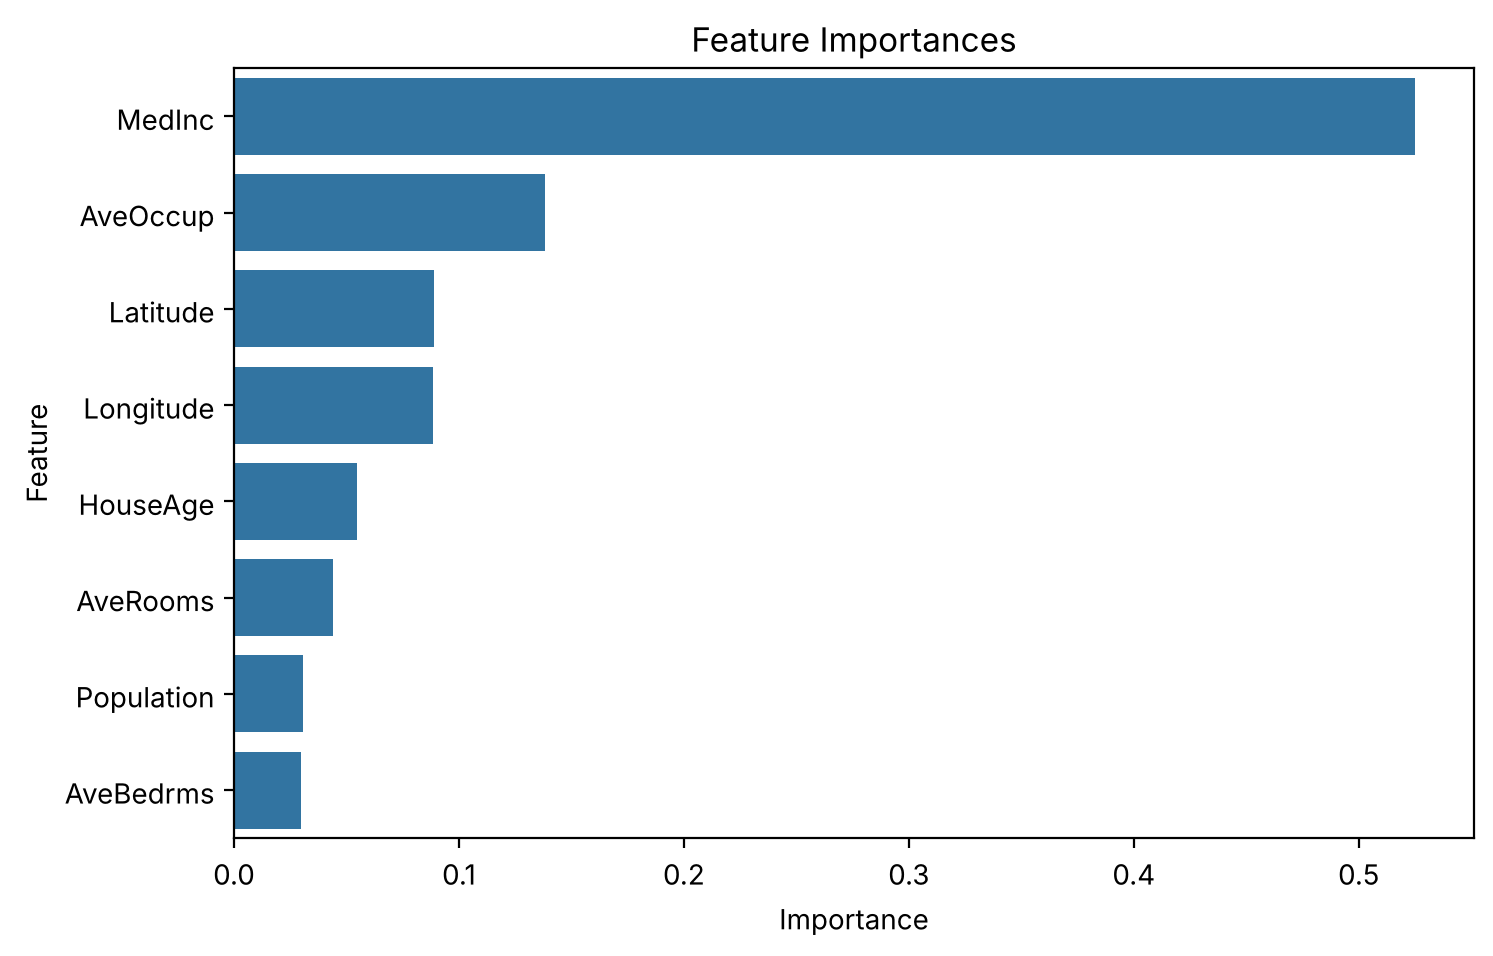

In [11]:
importances = final_model.feature_importances_
feature_names = X.columns

feature_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_df = feature_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x='Importance', y='Feature', data=feature_df)
plt.title('Feature Importances')
plt.show()

- **Insights:** `MedInc` (Median Income) is by far the most crucial determinant of house prices in this dataset, followed by location (`Longitude` and `Latitude`).
- **Business Application:** Real estate agents should heavily weight the income demographics of a neighborhood when pricing new listings.